In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.linear_model import RidgeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [2]:
fileName = r"C:\Users\justi\OneDrive\Documents\GEOL_415\Assignments\09-09\LA_AQS_2023.csv"
df = pd.read_csv(fileName)

In [3]:
print(df.columns)
print(df.head())

Index(['State Code', 'County Code', 'Site Number', 'Parameter Code', 'POC',
       'Latitude', 'Longitude', 'Datum', 'Parameter Name',
       'Duration Description', 'Pollutant Standard', 'Date (Local)', 'Year',
       'Day In Year (Local)', 'Units of Measure', 'Exceptional Data Type',
       'Nonreg Observation Count', 'Observation Count', 'Observation Percent',
       'Nonreg Arithmetic Mean', 'Arithmetic Mean',
       'Nonreg First Maximum Value', 'First Maximum Value',
       'First Maximum Hour', 'AQI', 'Daily Criteria Indicator', 'Tribe Name',
       'State Name', 'County Name', 'City Name', 'Local Site Name', 'Address',
       'MSA or CBSA Name', 'Data Source'],
      dtype='str')
   State Code  County Code  Site Number  Parameter Code  POC  Latitude  \
0           6           37         1103           68103    1  34.06659   
1           6           37         1103           42602    3  34.06659   
2           6           37         1103           62201    1  34.06659   
3      

In [4]:
date = 'Date (Local)'
parameter = 'Parameter Name'
value = 'Arithmetic Mean'

In [5]:
df['Date (Local)'] = pd.to_datetime(df['Date (Local)'], errors='coerce')
df['Arithmetic Mean'] = pd.to_numeric(df['Arithmetic Mean'], errors='coerce')

In [6]:
pollutants = ['Ozone', 'Nitrogen dioxide (NO2)', 'PM2.5 - Local Conditions']
data = df[df['Parameter Name'].isin(pollutants)].copy()


In [7]:
index_cols = [date, 'State Name', 'County Name', 'Site Number']

wide = data.pivot_table(
    index=index_cols,
    columns='Parameter Name',
    values='Arithmetic Mean',
    aggfunc='mean'
).reset_index()

print(wide.columns)

Index(['Date (Local)', 'State Name', 'County Name', 'Site Number',
       'Nitrogen dioxide (NO2)', 'Ozone', 'PM2.5 - Local Conditions'],
      dtype='str', name='Parameter Name')


In [8]:
wide = wide.rename(columns={'Ozone': 'O3', 'Nitrogen dioxide (NO2)': 'NO2', 'PM2.5 - Local Conditions': 'PM25'})

In [9]:
data = df[df['Parameter Name'].isin(['Ozone', 'Nitrogen dioxide (NO2)', 'PM2.5 - Local Conditions'])].copy()

In [10]:
o3 = data[data['Parameter Name'] == 'Ozone'][['Date (Local)', 'Arithmetic Mean']]
o3 = o3.rename(columns={'Arithmetic Mean': 'O3'})

no2 = data[data['Parameter Name'] == 'Nitrogen dioxide (NO2)'][['Date (Local)', 'Arithmetic Mean']]
no2 = no2.rename(columns={'Arithmetic Mean': 'NO2'})

pm25 = data[data['Parameter Name'] == 'PM2.5 - Local Conditions'][['Date (Local)', 'Arithmetic Mean']]
pm25 = pm25.rename(columns={'Arithmetic Mean': 'PM25'})

In [11]:
df_alln = o3.merge(no2, on="Date (Local)")
df_alln.head()

,Date (Local),O3,NO2
0,2023-01-01,0.031708,4.816667
1,2023-01-01,0.031708,4.550000
2,2023-01-01,0.031708,4.550000
3,2023-01-01,0.031708,4.816667
4,2023-01-01,0.028412,4.816667


In [12]:
df_allp = o3.merge(pm25, on="Date (Local)")
df_allp.head()

,Date (Local),O3,PM25
0,2023-01-01,0.031708,3.6000
1,2023-01-01,0.031708,3.6000
2,2023-01-01,0.031708,5.0875
3,2023-01-01,0.031708,5.0000
4,2023-01-01,0.031708,5.0000


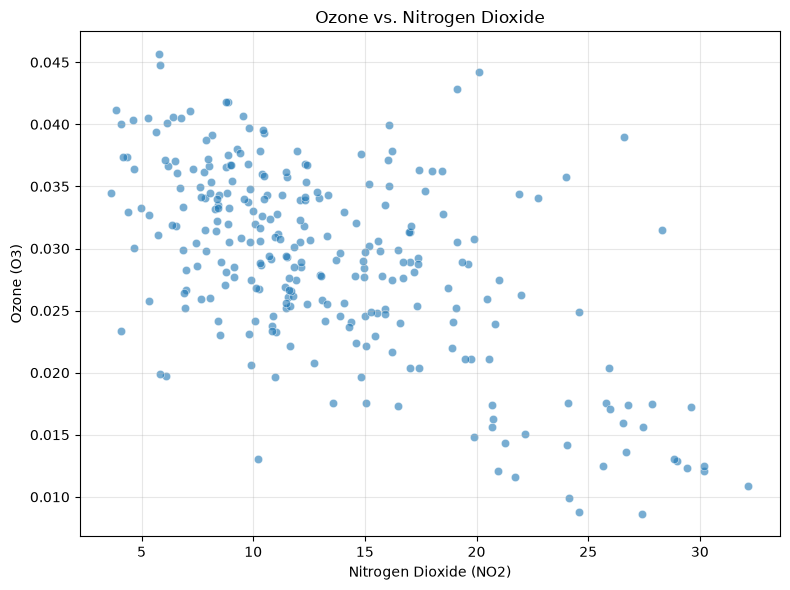

In [13]:
plot_no2 = wide.dropna(subset=['O3', 'NO2'])

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_no2, x='NO2', y='O3', alpha=0.6)
plt.xlabel('Nitrogen Dioxide (NO2)')
plt.ylabel('Ozone (O3)')
plt.title('Ozone vs. Nitrogen Dioxide')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

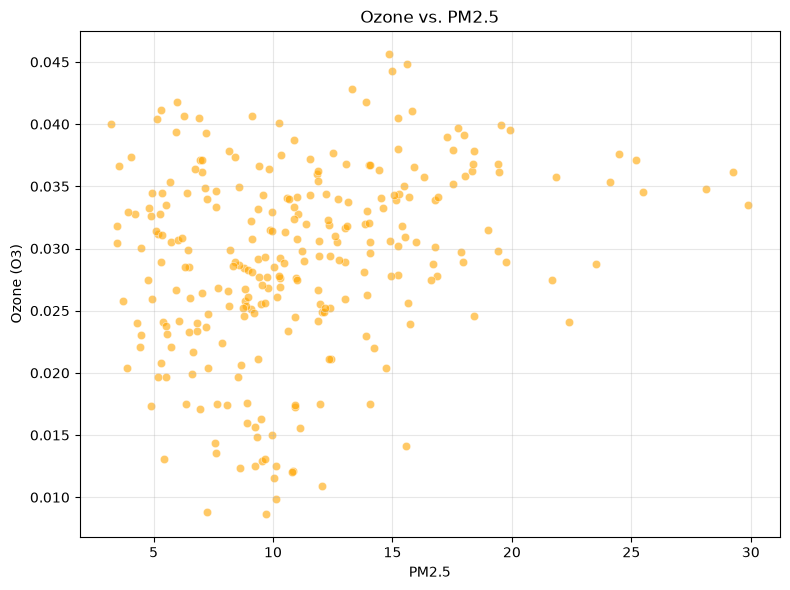

In [14]:
plot_pm25 = wide.dropna(subset=['O3', 'PM25'])

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_pm25, x='PM25', y='O3', alpha=0.6, color='orange')
plt.xlabel('PM2.5')
plt.ylabel('Ozone (O3)')
plt.title('Ozone vs. PM2.5')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
features = ['O3', 'NO2', 'PM25']

model_data = wide.dropna(subset=features + ['Date (Local)']).copy()

In [16]:
month = model_data['Date (Local)'].dt.month
model_data = model_data[month.isin([6, 7, 8, 12, 1, 2])].copy()
model_data['Season'] = model_data['Date (Local)'].dt.month.map(
    lambda m: 'Summer' if m in [6, 7, 8] else 'Winter'
)

In [17]:
X = model_data[features]
y = model_data['Season']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
ridge = RidgeClassifier()
ridge.fit(X_train, y_train)

,"alpha alpha: float, default=1.0Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.For an illustration of the effect of alpha on the model coefficients, see:ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If set to false, nointercept will be used in calculations (e.g. data is expected to bealready centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.The default value is determined by scipy.sparse.linalg.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard scipy.linalg.solve function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in scipy.sparse.linalg.cg. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine scipy.sparse.linalg.lsqr. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its unbiased and more flexible version named SAGA. Both methods use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from sklearn.preprocessing. .. versionadded:: 0.17 Stochastic Average Gradient descent solver. .. versionadded:: 0.19 SAGA solver.- 'lbfgs' uses L-BFGS-B algorithm implemented in `scipy.optimize.minimize`. It can be used only when `positive` is True.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary <random_state>` for details.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_class

In [20]:
y_pred = ridge.predict(X_test)


In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [22]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=['Winter', 'Summer']))

Accuracy: 0.9032258064516129

Classification Report:
              precision    recall  f1-score   support

      Summer       0.90      0.95      0.92        19
      Winter       0.91      0.83      0.87        12

    accuracy                           0.90        31
   macro avg       0.90      0.89      0.90        31
weighted avg       0.90      0.90      0.90        31


Confusion Matrix:
[[10  2]
 [ 1 18]]


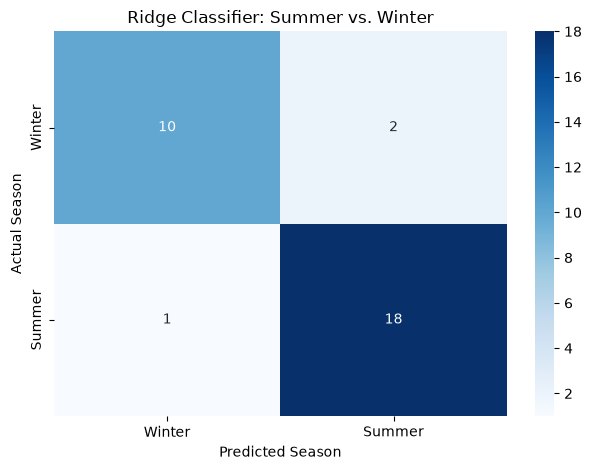

In [23]:
sns.heatmap(
    confusion_matrix(y_test, y_pred, labels=['Winter', 'Summer']),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Winter', 'Summer'],
    yticklabels=['Winter', 'Summer']
)

plt.xlabel('Predicted Season')
plt.ylabel('Actual Season')
plt.title('Ridge Classifier: Summer vs. Winter')
plt.tight_layout()
plt.show()

In [24]:
from sklearn.linear_model import RidgeClassifier
from sklearn.model_selection import GridSearchCV

In [25]:
param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

In [26]:
grid_search = GridSearchCV(
    estimator=RidgeClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train, y_train)

print("Optimal ridge penalty (alpha):", grid_search.best_params_['alpha'])
print("Best cross-validation accuracy:", grid_search.best_score_)

Optimal ridge penalty (alpha): 0.001
Best cross-validation accuracy: 0.8833333333333332


In [27]:
best_ridge = grid_search.best_estimator_

In [28]:
y_pred = best_ridge.predict(X_test)

from sklearn.metrics import accuracy_score
print("Test accuracy:", accuracy_score(y_test, y_pred))

Test accuracy: 0.8064516129032258


In [29]:
y_pred = grid_search.best_estimator_.predict(X_test)


In [30]:
test_accuracy = accuracy_score(y_test, y_pred)
test_error = 1 - test_accuracy

print("Optimal alpha:", grid_search.best_params_['alpha'])
print("Test accuracy:", round(test_accuracy, 4))
print("Final test error:", round(test_error, 4))
print("Final test error (%):", round(test_error * 100, 2), "%")

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Optimal alpha: 0.001
Test accuracy: 0.8065
Final test error: 0.1935
Final test error (%): 19.35 %

Classification report:
              precision    recall  f1-score   support

      Summer       0.78      0.95      0.86        19
      Winter       0.88      0.58      0.70        12

    accuracy                           0.81        31
   macro avg       0.83      0.77      0.78        31
weighted avg       0.82      0.81      0.80        31



In [32]:
from sklearn.linear_model import RidgeClassifier, LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [33]:
ridge_grid = GridSearchCV(
    RidgeClassifier(),
    {'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    cv=5,
    scoring='accuracy'
)
ridge_grid.fit(X_train, y_train)
ridge_best = ridge_grid.best_estimator_

In [34]:
log_grid = GridSearchCV(
    make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ),
    {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    cv=5,
    scoring='accuracy'
)
log_grid.fit(X_train, y_train)
log_best = log_grid.best_estimator_

In [36]:
ridge_pred = ridge_best.predict(X_test)
log_pred = log_best.predict(X_test)

ridge_accuracy = accuracy_score(y_test, ridge_pred)
log_accuracy = accuracy_score(y_test, log_pred)

print("Ridge best alpha:", ridge_grid.best_params_['alpha'])
print("Ridge test accuracy:", round(ridge_accuracy, 4))
print("Ridge test error (%):", round((1 - ridge_accuracy) * 100, 2))

print("\nLogistic Regression best C:",
      log_grid.best_params_['logisticregression__C'])
print("Logistic Regression test accuracy:", round(log_accuracy, 4))
print("Logistic Regression test error (%):",
      round((1 - log_accuracy) * 100, 2))

Ridge best alpha: 0.001
Ridge test accuracy: 0.8065
Ridge test error (%): 19.35

Logistic Regression best C: 100
Logistic Regression test accuracy: 0.871
Logistic Regression test error (%): 12.9


In [ ]:
#2. I am using the squared-error loss function
#3. 0.001
#4. 80.65%
#5. 19.35%
#6. No
#7. 